# 16 · Problemas clásicos de probabilidad

Nueve problemas célebres, cada uno con su enunciado, una demostración de la respuesta exacta y una simulación. El código usa **programación orientada a objetos**: una clase base abstracta `ProblemaClasico` fija la interfaz (`exacta`, `un_ensayo`, `simula`, `compara`) y cada problema es una subclase.

**Contenido**

0. La clase base `ProblemaClasico`
1. Las apuestas del caballero de Méré
2. La paradoja del cumpleaños
3. Monty Hall
4. La caja de Bertrand
5. Los tres prisioneros
6. Permutaciones aleatorias: el problema de los sombreros (*matching*)
7. El coleccionista de cupones
8. La aguja de Buffon
9. Resumen

In [1]:
from abc import ABC, abstractmethod
from fractions import Fraction
from math import comb, factorial, pi

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

rng = np.random.default_rng(2026)

## 0. La clase base `ProblemaClasico`

Cada problema sabe calcular su respuesta **exacta** y realizar **un ensayo** aleatorio que devuelve `True` o `False` (o un número, si la respuesta es una esperanza). La simulación y la comparación se heredan: la estimación de Monte Carlo es la media de los ensayos y su error estándar es $s/\sqrt n$. Una subclase puede sobrescribir `simula` con una versión vectorizada.

In [2]:
class ProblemaClasico(ABC):
    """Interfaz común: respuesta exacta, un ensayo aleatorio y simulación de Monte Carlo."""

    nombre = "problema"
    pregunta = ""

    def __init__(self, rng=rng):
        self.rng = rng

    @abstractmethod
    def exacta(self):
        """Respuesta exacta (probabilidad o esperanza)."""

    @abstractmethod
    def un_ensayo(self):
        """Un experimento aleatorio; devuelve un bool o un número."""

    def simula(self, n=20_000):
        """Ensayos independientes como arreglo de floats."""
        return np.array([self.un_ensayo() for _ in range(n)], dtype=float)

    def compara(self, n=20_000):
        x = self.simula(n)
        estimacion, error = x.mean(), x.std(ddof=1) / np.sqrt(len(x))   # len(x) puede ser < n si hay rechazo
        exacta = float(self.exacta())
        return pd.Series({"problema": self.nombre, "pregunta": self.pregunta, "exacta": exacta,
                          "simulación": estimacion, "error estándar": error,
                          "|dif| / error": abs(estimacion - exacta) / error if error > 0 else np.nan})

    def __repr__(self):
        return f"{type(self).__name__}({self.nombre!r}: exacta = {float(self.exacta()):.6f})"

## 1. Las apuestas del caballero de Méré

Antoine Gombaud, caballero de Méré, planteó a Pascal (1654) por qué ganaba apostando a

- **A**: al menos un $6$ en $4$ lanzamientos de un dado,

pero perdía apostando a

- **B**: al menos un doble seis en $24$ lanzamientos de dos dados,

si la «regla proporcional» de la época decía que ambas apuestas eran iguales ($4\cdot\frac16=24\cdot\frac1{36}=\frac23$).

**Proposición.** $\mathbb P(A)=1-\big(\frac56\big)^4\approx0.5177$ y $\mathbb P(B)=1-\big(\frac{35}{36}\big)^{24}\approx0.4914$.

*Demostración.* Los lanzamientos son independientes. El complemento de $A$ es «ningún seis en $4$ lanzamientos», con probabilidad $(5/6)^4$. El complemento de $B$ es «ningún doble seis en $24$ lanzamientos de dos dados», con probabilidad $(35/36)^{24}$. $\blacksquare$

La regla proporcional confunde $\mathbb P(\bigcup A_i)$ con $\sum\mathbb P(A_i)$, que solo coinciden para eventos ajenos. ¿Cuántos lanzamientos hacen favorable la apuesta B? Se necesita $1-(35/36)^n>\frac12$, es decir $n>\frac{\ln 2}{\ln(36/35)}\approx 24.6$: hacen falta $25$.

In [3]:
class DeMere(ProblemaClasico):
    def __init__(self, lanzamientos, dados, rng=rng):
        super().__init__(rng)
        self.lanzamientos, self.dados = lanzamientos, dados
        self.nombre = f"De Méré: {lanzamientos} lanz. de {dados} dado(s)"
        self.pregunta = "P(al menos un " + ("6" if dados == 1 else "doble seis") + ")"

    def exacta(self):
        return 1 - Fraction(6**self.dados - 1, 6**self.dados) ** self.lanzamientos

    def un_ensayo(self):
        caras = self.rng.integers(1, 7, size=(self.lanzamientos, self.dados))
        return bool(np.any(np.all(caras == 6, axis=1)))

    def simula(self, n=20_000):
        caras = self.rng.integers(1, 7, size=(n, self.lanzamientos, self.dados))
        return np.any(np.all(caras == 6, axis=2), axis=1).astype(float)


A, B = DeMere(4, 1), DeMere(24, 2)
print(A, B, sep="\n")
print("lanzamientos mínimos para que B sea favorable:", next(n for n in range(1, 100) if DeMere(n, 2).exacta() > Fraction(1, 2)))
pd.DataFrame([A.compara(200_000), B.compara(200_000)])

DeMere('De Méré: 4 lanz. de 1 dado(s)': exacta = 0.517747)
DeMere('De Méré: 24 lanz. de 2 dado(s)': exacta = 0.491404)
lanzamientos mínimos para que B sea favorable: 25


,problema,pregunta,exacta,simulación,error estándar,|dif| / error
0,De Méré: 4 lanz. de 1 dado(s),P(al menos un 6),0.517747,0.515330,0.001118,2.162765
1,De Méré: 24 lanz. de 2 dado(s),P(al menos un doble seis),0.491404,0.491195,0.001118,0.186853


## 2. La paradoja del cumpleaños

¿Cuántas personas hacen falta para que la probabilidad de que dos compartan cumpleaños supere $\frac12$? (Se ignoran los años bisiestos y se suponen los $365$ días equiprobables.)

**Proposición.** Con $k$ personas,

$$p_k=\mathbb P(\text{al menos dos comparten cumpleaños})=1-\prod_{i=0}^{k-1}\Big(1-\frac{i}{365}\Big)=1-\frac{365!}{(365-k)!\,365^k},$$

y $p_k>\frac12$ por primera vez en $k=23$, con $p_{23}\approx0.5073$.

*Demostración.* El espacio muestral son las $365^k$ asignaciones de cumpleaños, equiprobables. Las asignaciones sin repetición son las sucesiones ordenadas sin reemplazo: $365\cdot364\cdots(365-k+1)$. Basta tomar el complemento. $\blacksquare$

**Por qué tan pocas.** Hay $\binom{k}{2}$ parejas, y cada una coincide con probabilidad $\frac1{365}$. Usando $1-x\le e^{-x}$,

$$1-p_k=\prod_{i<k}\Big(1-\frac i{365}\Big)\le\exp\Big(-\sum_{i<k}\frac{i}{365}\Big)=\exp\Big(-\frac{\binom k2}{365}\Big),$$

y la aproximación $p_k\approx1-e^{-k(k-1)/730}$ es muy precisa. Con $23$ personas hay $253$ parejas.

mínimo k: 23   p_23 = 0.5073


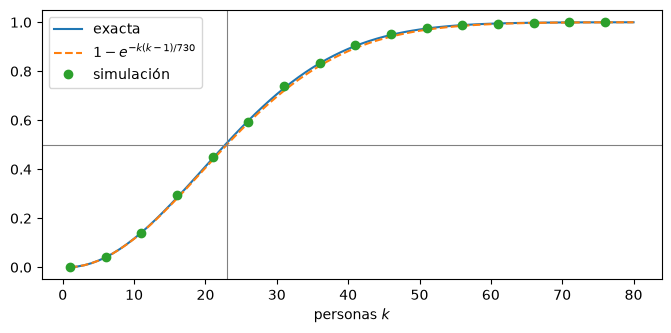

,problema,pregunta,exacta,simulación,error estándar,|dif| / error
0,"Cumpleaños, k = 10",P(alguna coincidencia),0.116948,0.11555,0.002261,0.618507
1,"Cumpleaños, k = 23",P(alguna coincidencia),0.507297,0.51070,0.003535,0.962644
2,"Cumpleaños, k = 50",P(alguna coincidencia),0.970374,0.96955,0.001215,0.677846


In [4]:
class Cumpleanos(ProblemaClasico):
    def __init__(self, k, dias=365, rng=rng):
        super().__init__(rng)
        self.k, self.dias = k, dias
        self.nombre, self.pregunta = f"Cumpleaños, k = {k}", "P(alguna coincidencia)"

    def exacta(self):
        return 1 - np.prod(1 - np.arange(self.k) / self.dias)

    def aproximacion(self):
        return 1 - np.exp(-self.k * (self.k - 1) / (2 * self.dias))

    def un_ensayo(self):
        return len(set(self.rng.integers(0, self.dias, self.k))) < self.k

    def simula(self, n=20_000):
        fechas = np.sort(self.rng.integers(0, self.dias, size=(n, self.k)), axis=1)
        return np.any(np.diff(fechas, axis=1) == 0, axis=1).astype(float)


k_min = next(k for k in range(1, 100) if Cumpleanos(k).exacta() > 0.5)
print("mínimo k:", k_min, "  p_23 =", round(Cumpleanos(23).exacta(), 4))

ks = np.arange(1, 81)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(ks, [Cumpleanos(k).exacta() for k in ks], label="exacta")
ax.plot(ks, [Cumpleanos(k).aproximacion() for k in ks], "--", label=r"$1-e^{-k(k-1)/730}$")
ax.plot(ks[::5], [Cumpleanos(k).simula(4000).mean() for k in ks[::5]], "o", label="simulación")
ax.axhline(0.5, color="gray", lw=0.8)
ax.axvline(23, color="gray", lw=0.8)
ax.set_xlabel("personas $k$")
ax.legend()
plt.show()
pd.DataFrame([Cumpleanos(k).compara() for k in (10, 23, 50)])

## 3. Monty Hall

En un concurso hay tres puertas: detrás de una hay un auto y detrás de las otras dos, cabras. El concursante elige una puerta. El presentador, que **sabe** dónde está el auto, abre otra puerta que **siempre** esconde una cabra, eligiendo al azar si tiene dos opciones. Luego ofrece cambiar de puerta. ¿Conviene cambiar?

**Proposición.** Quedarse gana con probabilidad $\frac13$; cambiar gana con probabilidad $\frac23$.

*Demostración.* La primera elección acierta con probabilidad $\frac13$, sin importar lo que haga el presentador después. Quien cambia gana exactamente cuando la primera elección era una cabra: probabilidad $\frac23$.

Con Bayes: supongamos que el concursante elige la puerta 1 y el presentador abre la 3. Sea $C_i$ = «el auto está en la puerta $i$». Entonces $\mathbb P(\text{abre }3\mid C_1)=\frac12$, $\mathbb P(\text{abre }3\mid C_2)=1$ y $\mathbb P(\text{abre }3\mid C_3)=0$, así que

$$\mathbb P(C_2\mid\text{abre }3)=\frac{1\cdot\frac13}{\frac12\cdot\frac13+1\cdot\frac13+0}=\frac23.\qquad\blacksquare$$

Con $n$ puertas, si el presentador abre $n-2$ puertas con cabras, cambiar gana con probabilidad $\frac{n-1}{n}$. Las hipótesis importan: si el presentador abriera una puerta **al azar** y por casualidad mostrara una cabra, cambiar y quedarse tendrían ambos probabilidad $\frac12$.

In [5]:
class MontyHall(ProblemaClasico):
    def __init__(self, cambiar, puertas=3, presentador_sabe=True, rng=rng):
        super().__init__(rng)
        self.cambiar, self.puertas, self.sabe = cambiar, puertas, presentador_sabe
        self.nombre = f"Monty Hall ({puertas} puertas, {'cambiar' if cambiar else 'quedarse'}" + ("" if presentador_sabe else ", presentador al azar") + ")"
        self.pregunta = "P(ganar el auto)" + ("" if presentador_sabe else " | se mostró cabra")

    def exacta(self):
        n = self.puertas
        if not self.sabe:
            return Fraction(1, 2) if n == 3 else None
        return Fraction(n - 1, n) if self.cambiar else Fraction(1, n)

    def un_ensayo(self):
        n = self.puertas
        auto, eleccion = self.rng.integers(n), self.rng.integers(n)
        otras = [p for p in range(n) if p != eleccion]
        if self.sabe:
            # abre n-2 puertas con cabra; queda cerrada una de las otras
            cerrada = auto if auto != eleccion else self.rng.choice(otras)
        else:
            cerrada = self.rng.choice(otras)                 # abre las demás al azar
            abiertas = [p for p in otras if p != cerrada]
            if auto in abiertas:
                return np.nan                                # se mostró el auto: no cuenta
        final = cerrada if self.cambiar else eleccion
        return final == auto

    def simula(self, n=20_000):
        x = super().simula(n)
        return x[~np.isnan(x)]                               # condiciona a que se mostró una cabra


pd.DataFrame([MontyHall(False).compara(), MontyHall(True).compara(),
              MontyHall(True, puertas=10).compara(),
              MontyHall(True, presentador_sabe=False).compara(), MontyHall(False, presentador_sabe=False).compara()])

,problema,pregunta,exacta,simulación,error estándar,|dif| / error
0,"Monty Hall (3 puertas, quedarse)",P(ganar el auto),0.333333,0.333950,0.003335,0.184910
1,"Monty Hall (3 puertas, cambiar)",P(ganar el auto),0.666667,0.666600,0.003334,0.019999
2,"Monty Hall (10 puertas, cambiar)",P(ganar el auto),0.900000,0.900150,0.002120,0.070756
3,"Monty Hall (3 puertas, cambiar, presentador al...",P(ganar el auto) | se mostró cabra,0.500000,0.494471,0.004322,1.279320
4,"Monty Hall (3 puertas, quedarse, presentador a...",P(ganar el auto) | se mostró cabra,0.500000,0.495568,0.004315,1.027048


## 4. La caja de Bertrand

Hay tres cajas: una con dos monedas de oro (OO), una con dos de plata (PP) y una con una de cada (OP). Se elige una caja al azar y de ella una moneda al azar: es de oro. ¿Cuál es la probabilidad de que la otra moneda de la caja también sea de oro?

**Proposición.** La respuesta es $\frac23$, no $\frac12$.

*Demostración.* Las $6$ monedas son equiprobables. Hay $3$ monedas de oro, y $2$ de ellas están en la caja OO. Formalmente,

$$\mathbb P(OO\mid\text{oro})=\frac{\mathbb P(\text{oro}\mid OO)\,\mathbb P(OO)}{\mathbb P(\text{oro})}=\frac{1\cdot\frac13}{\frac12}=\frac23.\qquad\blacksquare$$

El argumento erróneo «la caja es OO u OP, y son igualmente probables» olvida que la caja OO produce oro con el doble de probabilidad que la caja OP.

In [6]:
class CajaBertrand(ProblemaClasico):
    nombre, pregunta = "Caja de Bertrand", "P(la otra es oro | salió oro)"
    cajas = [("O", "O"), ("P", "P"), ("O", "P")]

    def exacta(self):
        monedas = [(c, i) for c in range(3) for i in range(2)]
        oro = [(c, i) for c, i in monedas if self.cajas[c][i] == "O"]
        return Fraction(sum(self.cajas[c][1 - i] == "O" for c, i in oro), len(oro))

    def un_ensayo(self):
        while True:                                   # muestreo con rechazo: hasta que salga oro
            c, i = self.rng.integers(3), self.rng.integers(2)
            if self.cajas[c][i] == "O":
                return self.cajas[c][1 - i] == "O"


CajaBertrand().compara().to_frame().T

,problema,pregunta,exacta,simulación,error estándar,|dif| / error
0,Caja de Bertrand,P(la otra es oro | salió oro),0.666667,0.6696,0.003326,0.881938


## 5. Los tres prisioneros

Tres prisioneros, A, B y C, saben que uno de ellos, elegido al azar, será indultado. A le pide al guardia, que sabe quién es el indultado, que le diga el nombre de **otro** prisionero que será ejecutado; si los dos serán ejecutados, el guardia elige al azar. El guardia responde «B». A razona: «ahora solo quedamos C y yo, así que mi probabilidad subió de $\frac13$ a $\frac12$». ¿Tiene razón?

**Proposición.** $\mathbb P(\text{A indultado}\mid\text{el guardia dice B})=\frac13$ y $\mathbb P(\text{C indultado}\mid\text{el guardia dice B})=\frac23$.

*Demostración.* $\mathbb P(\text{dice B}\mid A)=\frac12$, $\mathbb P(\text{dice B}\mid B)=0$ y $\mathbb P(\text{dice B}\mid C)=1$. Por Bayes,

$$\mathbb P(A\mid\text{dice B})=\frac{\frac12\cdot\frac13}{\frac12\cdot\frac13+0+1\cdot\frac13}=\frac13.\qquad\blacksquare$$

Es el mismo problema que Monty Hall: la respuesta del guardia no da información sobre A (el guardia siempre puede nombrar a alguien), pero sí sobre C.

In [7]:
class TresPrisioneros(ProblemaClasico):
    def __init__(self, quien="A", rng=rng):
        super().__init__(rng)
        self.quien = quien
        self.nombre, self.pregunta = "Tres prisioneros", f"P({quien} indultado | el guardia dice B)"

    def exacta(self):
        verosimilitud = {"A": Fraction(1, 2), "B": Fraction(0), "C": Fraction(1)}   # P(dice B | indultado)
        return verosimilitud[self.quien] / sum(verosimilitud.values())

    def un_ensayo(self):
        while True:
            indultado = self.rng.choice(["A", "B", "C"])
            dice = self.rng.choice(["B", "C"]) if indultado == "A" else ("C" if indultado == "B" else "B")
            if dice == "B":
                return indultado == self.quien


pd.DataFrame([TresPrisioneros("A").compara(), TresPrisioneros("C").compara()])

,problema,pregunta,exacta,simulación,error estándar,|dif| / error
0,Tres prisioneros,P(A indultado | el guardia dice B),0.333333,0.3346,0.003337,0.379631
1,Tres prisioneros,P(C indultado | el guardia dice B),0.666667,0.6661,0.003335,0.169924


## 6. Permutaciones aleatorias: el problema de los sombreros

$n$ personas dejan su sombrero en el guardarropa y al salir reciben uno al azar: una **permutación aleatoria uniforme** $\sigma$ de $\{1,\dots,n\}$. Un **punto fijo** (*matching*) es una persona que recibe su propio sombrero. ¿Cuál es la probabilidad de que nadie reciba el suyo? (Problema de Montmort, 1708.)

**Proposición.** Sea $F_n$ el número de puntos fijos. Entonces

$$\mathbb P(F_n=0)=\sum_{j=0}^n\frac{(-1)^j}{j!}\xrightarrow[n\to\infty]{}\frac1e\approx0.3679,$$

y más generalmente $\mathbb P(F_n=m)=\dfrac1{m!}\displaystyle\sum_{j=0}^{n-m}\frac{(-1)^j}{j!}\to e^{-1}\dfrac{1}{m!}$: $F_n$ converge en ley a una $\mathrm{Poisson}(1)$. Además $\mathbb E[F_n]=\operatorname{Var}(F_n)=1$ para todo $n\ge2$.

*Demostración.* Sea $A_i=\{\sigma(i)=i\}$. Para $i_1<\cdots<i_j$, $\mathbb P(A_{i_1}\cap\cdots\cap A_{i_j})=\frac{(n-j)!}{n!}$, porque las demás $n-j$ posiciones se permutan libremente. Por inclusión–exclusión,

$$\mathbb P\Big(\bigcup_i A_i\Big)=\sum_{j=1}^n(-1)^{j+1}\binom nj\frac{(n-j)!}{n!}=\sum_{j=1}^n\frac{(-1)^{j+1}}{j!},$$

y $\mathbb P(F_n=0)=1-\mathbb P(\bigcup A_i)$. Para $F_n=m$ se eligen los $\binom nm$ puntos fijos y el resto es un desarreglo de $n-m$ elementos. Para los momentos, $F_n=\sum_i\mathbf 1_{A_i}$ con $\mathbb P(A_i)=\frac1n$ y $\mathbb P(A_i\cap A_j)=\frac1{n(n-1)}$, así que $\mathbb E[F_n]=1$ y $\mathbb E[F_n^2]=1+n(n-1)\cdot\frac{1}{n(n-1)}=2$. $\blacksquare$

El número de **desarreglos** es $D_n=n!\sum_{j=0}^n\frac{(-1)^j}{j!}$, el entero más cercano a $n!/e$.

desarreglos D_n: [0, 1, 2, 9, 44, 265, 1854, 14833]
P(F_n = 0): {2: 0.5, 3: 0.333333, 5: 0.366667, 10: 0.367879, 20: 0.367879}  1/e = 0.367879


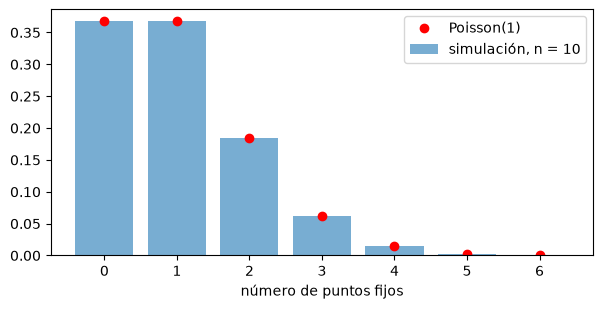

E[F] ≈ 0.998,  Var(F) ≈ 0.991


,problema,pregunta,exacta,simulación,error estándar,|dif| / error
0,"Sombreros, n = 10",P(exactamente 0 reciben el suyo),0.367879,0.36555,0.003405,0.684050
1,"Sombreros, n = 10",P(exactamente 1 reciben el suyo),0.367879,0.37210,0.003418,1.234881
2,"Sombreros, n = 10",P(exactamente 2 reciben el suyo),0.183941,0.18545,0.002748,0.549072


In [8]:
class Sombreros(ProblemaClasico):
    def __init__(self, n, m=0, rng=rng):
        super().__init__(rng)
        self.n, self.m = n, m
        self.nombre, self.pregunta = f"Sombreros, n = {n}", f"P(exactamente {m} reciben el suyo)"

    def exacta(self):
        n, m = self.n, self.m
        return Fraction(1, factorial(m)) * sum(Fraction((-1) ** j, factorial(j)) for j in range(n - m + 1))

    def puntos_fijos(self, size):
        perm = np.argsort(self.rng.random((size, self.n)), axis=1)     # permutaciones uniformes
        return (perm == np.arange(self.n)).sum(axis=1)

    def un_ensayo(self):
        return self.puntos_fijos(1)[0] == self.m

    def simula(self, n=20_000):
        return (self.puntos_fijos(n) == self.m).astype(float)


print("desarreglos D_n:", [round(factorial(n) * float(Sombreros(n).exacta())) for n in range(1, 9)])
print("P(F_n = 0):", {n: round(float(Sombreros(n).exacta()), 6) for n in (2, 3, 5, 10, 20)}, " 1/e =", round(np.exp(-1), 6))

F = Sombreros(10).puntos_fijos(100_000)
m = np.arange(7)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(m, [np.mean(F == j) for j in m], alpha=0.6, label="simulación, n = 10")
ax.plot(m, stats.poisson.pmf(m, 1), "ro", label="Poisson(1)")
ax.legend()
ax.set_xlabel("número de puntos fijos")
plt.show()
print(f"E[F] ≈ {F.mean():.3f},  Var(F) ≈ {F.var():.3f}")
pd.DataFrame([Sombreros(10, 0).compara(), Sombreros(10, 1).compara(), Sombreros(10, 2).compara()])

### Ciclos de una permutación aleatoria

Toda permutación se descompone en ciclos disjuntos; los puntos fijos son los ciclos de longitud $1$. Para una permutación uniforme de $\{1,\dots,n\}$, la longitud del ciclo que contiene a $1$ es **uniforme** en $\{1,\dots,n\}$: la probabilidad de que tenga longitud $\ell$ es

$$\frac{(n-1)(n-2)\cdots(n-\ell+1)\cdot(n-\ell)!}{n!}=\frac1n,$$

pues se eligen en orden los $\ell-1$ elementos siguientes del ciclo y luego se permuta el resto. En consecuencia, la probabilidad de que haya un ciclo de longitud mayor que $n/2$ (a lo más hay uno) es $\sum_{\ell>n/2}\frac1\ell\to\ln2$. Este es el origen del célebre acertijo de los $100$ prisioneros.

In [9]:
class CicloDelUno(ProblemaClasico):
    def __init__(self, n, rng=rng):
        super().__init__(rng)
        self.n = n
        self.nombre, self.pregunta = f"Ciclos, n = {n}", "P(hay un ciclo de longitud > n/2)"

    def exacta(self):
        return sum(Fraction(1, l) for l in range(self.n // 2 + 1, self.n + 1))

    @staticmethod
    def ciclos(perm):
        visto, longitudes = np.zeros(len(perm), bool), []
        for i in range(len(perm)):
            if not visto[i]:
                l, j = 0, i
                while not visto[j]:
                    visto[j], j, l = True, perm[j], l + 1
                longitudes.append(l)
        return longitudes

    def un_ensayo(self):
        return max(self.ciclos(self.rng.permutation(self.n))) > self.n / 2


largos = [CicloDelUno.ciclos(rng.permutation(20))[0] for _ in range(20_000)]   # ciclo que contiene al 0
print("longitud del ciclo del primer elemento, n = 20: frecuencias de 1..5 ≈", np.round(np.bincount(largos, minlength=21)[1:6] / 20_000, 4), " 1/n =", 1 / 20)
pd.DataFrame([CicloDelUno(100).compara(5000)]).assign(ln2=np.log(2))

longitud del ciclo del primer elemento, n = 20: frecuencias de 1..5 ≈ [0.0513 0.0482 0.0508 0.0492 0.0512]  1/n = 0.05


,problema,pregunta,exacta,simulación,error estándar,|dif| / error,ln2
0,"Ciclos, n = 100",P(hay un ciclo de longitud > n/2),0.688172,0.6844,0.006573,0.573866,0.693147


## 7. El coleccionista de cupones

Cada paquete trae uno de $n$ cupones distintos, uniformemente al azar. ¿Cuántos paquetes hay que comprar, en promedio, para completar la colección?

**Proposición.** Sea $T_n$ el número de paquetes. Entonces

$$\mathbb E[T_n]=n\sum_{k=1}^n\frac1k=nH_n\sim n\ln n,\qquad \operatorname{Var}(T_n)=n^2\sum_{k=1}^n\frac1{k^2}-nH_n<\frac{\pi^2}{6}n^2.$$

*Demostración.* Escribimos $T_n=G_1+G_2+\cdots+G_n$, donde $G_i$ es el número de paquetes desde que se tienen $i-1$ cupones distintos hasta obtener el $i$-ésimo. Con $i-1$ cupones, cada paquete trae uno nuevo con probabilidad $p_i=\frac{n-i+1}{n}$, independientemente del pasado; así $G_i\sim\mathrm{Geo}(p_i)$ y las $G_i$ son independientes. Por tanto

$$\mathbb E[T_n]=\sum_{i=1}^n\frac{n}{n-i+1}=n\sum_{k=1}^n\frac1k,\qquad \operatorname{Var}(T_n)=\sum_{i=1}^n\frac{1-p_i}{p_i^2}.\qquad\blacksquare$$

Además, $\dfrac{T_n-n\ln n}{n}$ converge en ley a la distribución de Gumbel, $\mathbb P(\cdot\le x)\to e^{-e^{-x}}$ (Erdős–Rényi).

n = 50:  E exacta = 224.96,  ensayo directo ≈ 225.09,  Var exacta = 3837.9, Var directa ≈ 3693.3


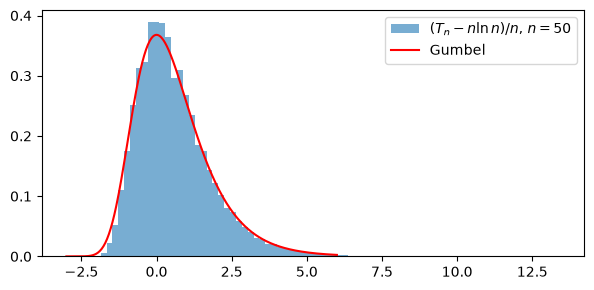

,problema,pregunta,exacta,simulación,error estándar,|dif| / error
0,"Coleccionista, n = 6",E[paquetes],14.700000,14.6168,0.043944,1.893319
1,"Coleccionista, n = 50",E[paquetes],224.960267,224.3502,0.435068,1.402234
2,"Coleccionista, n = 365",E[paquetes],2364.646023,2362.4726,3.278347,0.662963


In [10]:
class Coleccionista(ProblemaClasico):
    def __init__(self, n, rng=rng):
        super().__init__(rng)
        self.n = n
        self.nombre, self.pregunta = f"Coleccionista, n = {n}", "E[paquetes]"

    def exacta(self):
        return self.n * sum(Fraction(1, k) for k in range(1, self.n + 1))

    def varianza(self):
        return float(self.n**2 * sum(Fraction(1, k * k) for k in range(1, self.n + 1)) - self.exacta())

    def un_ensayo(self):
        vistos, paquetes = set(), 0
        while len(vistos) < self.n:
            vistos.add(int(self.rng.integers(self.n)))
            paquetes += 1
        return paquetes

    def simula(self, n=20_000):
        # suma de geométricas independientes (la demostración, convertida en algoritmo)
        p = (self.n - np.arange(self.n)) / self.n
        return self.rng.geometric(p, size=(n, self.n)).sum(axis=1).astype(float)


c = Coleccionista(50)
directo = np.array([c.un_ensayo() for _ in range(3000)])
print(f"n = 50:  E exacta = {float(c.exacta()):.2f},  ensayo directo ≈ {directo.mean():.2f},  Var exacta = {c.varianza():.1f}, Var directa ≈ {directo.var():.1f}")

T = c.simula(100_000)
z = (T - c.n * np.log(c.n)) / c.n
x = np.linspace(-3, 6, 300)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(z, bins=80, density=True, alpha=0.6, label=r"$(T_n-n\ln n)/n$, $n=50$")
ax.plot(x, stats.gumbel_r.pdf(x), "r", label="Gumbel")
ax.legend()
plt.show()
pd.DataFrame([Coleccionista(n).compara() for n in (6, 50, 365)])

## 8. La aguja de Buffon

Se deja caer una aguja de longitud $\ell$ sobre un piso con rectas paralelas separadas una distancia $d\ge\ell$. ¿Cuál es la probabilidad de que la aguja cruce una recta? (Buffon, 1777.)

**Proposición.** $\mathbb P(\text{cruce})=\dfrac{2\ell}{\pi d}$.

*Demostración.* Sea $X\in[0,d/2]$ la distancia del centro de la aguja a la recta más cercana y $\Theta\in[0,\pi/2]$ el ángulo agudo entre la aguja y las rectas. El modelo «al azar» es: $X$ y $\Theta$ independientes y uniformes. La aguja cruza si y solo si $X\le\frac\ell2\sin\Theta$. Entonces

$$\mathbb P(\text{cruce})=\int_0^{\pi/2}\!\!\int_0^{\frac\ell2\sin\theta}\frac{2}{d}\cdot\frac2\pi\,dx\,d\theta=\frac{4}{\pi d}\cdot\frac\ell2\int_0^{\pi/2}\sin\theta\,d\theta=\frac{2\ell}{\pi d}.\qquad\blacksquare$$

Así, contar cruces da un estimador de $\pi$: $\hat\pi=\dfrac{2\ell n}{d\cdot(\text{número de cruces})}$. Es un estimador poco eficiente: su error relativo decrece solo como $1/\sqrt n$.

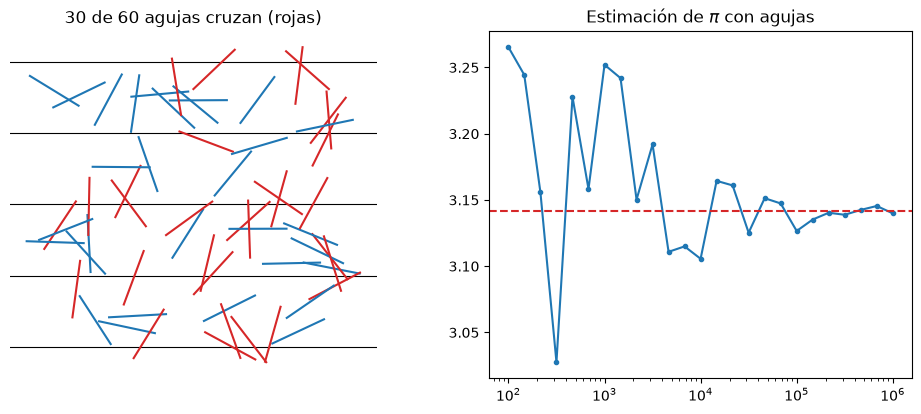

,problema,pregunta,exacta,simulación,error estándar,|dif| / error
0,"Buffon, l = 0.8, d = 1.0",P(la aguja cruza),0.509296,0.509091,0.0005,0.409703


In [11]:
class Buffon(ProblemaClasico):
    def __init__(self, l=1.0, d=1.0, rng=rng):
        super().__init__(rng)
        if l > d:
            raise ValueError("se supone l <= d")
        self.l, self.d = l, d
        self.nombre, self.pregunta = f"Buffon, l = {l}, d = {d}", "P(la aguja cruza)"

    def exacta(self):
        return 2 * self.l / (pi * self.d)

    def un_ensayo(self):
        x, theta = self.rng.uniform(0, self.d / 2), self.rng.uniform(0, pi / 2)
        return x <= self.l / 2 * np.sin(theta)

    def simula(self, n=20_000):
        x, theta = self.rng.uniform(0, self.d / 2, n), self.rng.uniform(0, pi / 2, n)
        return (x <= self.l / 2 * np.sin(theta)).astype(float)

    def estima_pi(self, n):
        return 2 * self.l * n / (self.d * self.simula(n).sum())

    def dibuja(self, n=60, ax=None):
        ax = ax or plt.gca()
        centros = np.c_[self.rng.uniform(0, 4 * self.d, n), self.rng.uniform(0, 4 * self.d, n)]
        angulos = self.rng.uniform(0, pi, n)
        dx, dy = self.l / 2 * np.cos(angulos), self.l / 2 * np.sin(angulos)
        y0, y1 = centros[:, 1] - dy, centros[:, 1] + dy
        cruza = np.floor(y0 / self.d) != np.floor(y1 / self.d)
        for y in np.arange(0, 4 * self.d + 1e-9, self.d):
            ax.axhline(y, color="k", lw=0.8)
        for (cx, cy), ddx, ddy, c in zip(centros, dx, dy, cruza):
            ax.plot([cx - ddx, cx + ddx], [cy - ddy, cy + ddy], color="tab:red" if c else "tab:blue", lw=1.5)
        ax.set_aspect("equal")
        ax.set_title(f"{cruza.sum()} de {n} agujas cruzan (rojas)")
        ax.axis("off")


b = Buffon(l=0.8, d=1.0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
b.dibuja(ax=ax1)
ns = np.unique(np.logspace(2, 6, 25).astype(int))
ax2.plot(ns, [b.estima_pi(n) for n in ns], "o-", ms=3)
ax2.axhline(pi, color="tab:red", ls="--")
ax2.set_xscale("log")
ax2.set_title(r"Estimación de $\pi$ con agujas")
plt.show()
b.compara(1_000_000).to_frame().T

## 9. Resumen

La interfaz común permite reunir todos los problemas en una tabla. La última columna mide la diferencia entre simulación y respuesta exacta en unidades de error estándar; valores menores que $2$ o $3$ son los esperados.

In [12]:
problemas = [DeMere(4, 1), DeMere(24, 2), Cumpleanos(23), MontyHall(True), CajaBertrand(), TresPrisioneros("A"),
             Sombreros(10), CicloDelUno(100), Coleccionista(50), Buffon(0.8, 1.0)]
resumen = pd.DataFrame([p.compara(20_000 if not isinstance(p, CicloDelUno) else 4000) for p in problemas])
resumen.style.format({"exacta": "{:.4f}", "simulación": "{:.4f}", "error estándar": "{:.4f}", "|dif| / error": "{:.2f}"})

,problema,pregunta,exacta,simulación,error estándar,|dif| / error
0,De Méré: 4 lanz. de 1 dado(s),P(al menos un 6),0.5177,0.5226,0.0035,1.37
1,De Méré: 24 lanz. de 2 dado(s),P(al menos un doble seis),0.4914,0.4915,0.0035,0.04
2,"Cumpleaños, k = 23",P(alguna coincidencia),0.5073,0.5039,0.0035,0.96
3,"Monty Hall (3 puertas, cambiar)",P(ganar el auto),0.6667,0.6673,0.0033,0.18
4,Caja de Bertrand,P(la otra es oro | salió oro),0.6667,0.6668,0.0033,0.04
5,Tres prisioneros,P(A indultado | el guardia dice B),0.3333,0.3332,0.0033,0.06
6,"Sombreros, n = 10",P(exactamente 0 reciben el suyo),0.3679,0.3665,0.0034,0.39
7,"Ciclos, n = 100",P(hay un ciclo de longitud > n/2),0.6882,0.6765,0.0074,1.58
8,"Coleccionista, n = 50",E[paquetes],224.9603,225.3483,0.4388,0.88
9,"Buffon, l = 0.8, d = 1.0",P(la aguja cruza),0.5093,0.5087,0.0035,0.17


## Ejercicios

1. Escribe una subclase `CumpleanosTres` para la probabilidad de que **tres** personas compartan cumpleaños. ¿Cuántas personas hacen falta para superar $\frac12$? (Respuesta: $88$.)
2. En Monty Hall con $n$ puertas, el presentador abre solo **una** puerta con cabra. Demuestra que cambiar (a una puerta al azar de las restantes) gana con probabilidad $\frac{n-1}{n(n-2)}$.
3. Demuestra que el número esperado de ciclos de una permutación uniforme de $n$ elementos es $H_n=\sum_{k\le n}\frac1k$.
4. La **aguja larga** ($\ell>d$): demuestra que el número esperado de cruces es $\frac{2\ell}{\pi d}$ para cualquier $\ell$, por linealidad de la esperanza (la «aguja de Barbier»).